In [ ]:
#parallel workflow for UPSC essay evaluation
# 3 llm based parallel workflows : Clarity of thought , Depth of analysis, language
# final evaluation 
# structured output : the structure of all 3 llm outputs should be same / JSON format
# reducer function

In [ ]:
#  import dependencies

from langgraph.graph import StateGraph , START, END
from typing import TypedDict, Annotated
from langchain_openai import ChatOpenAI
from langchain_groq import ChatGroq
from dotenv import load_dotenv
import os
from langgraph.checkpoint.memory import MemorySaver
import operator # 
from pydantic import BaseModel, Field
# Field lets you add extra rules and metadata to individual fields.---> in simple terms, these are contraints
# BaseModel lets you define what fields an object should contain and what types those fields should have.
# Pydantic helps you define the structure of data and validate whether the data follows your rules.

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    groq_api_key="your API key"
)
print(model)

metadata={'lc_versions': {'langchain-core': '1.6.7', 'langchain': '1.4.3'}} profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True} client=<groq.resources.chat.completions.Completions object at 0x000001C550FC22C0> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001C550FC2C40> model_name='openai/gpt-oss-120b' temperature=1e-08 model_kwargs={} groq_api_key=SecretStr('**********')


In [38]:
# model = ChatOpenAI(model = 'gpt-4o-mini')

class EvaluationSchema(BaseModel):
    feedback : str = Field(description = 'detailed feedback for the essay')
    score : float = Field(description = 'score out of 10', ge= 0, le= 10)

In [39]:
Structured_output = model.with_structured_output(EvaluationSchema)

In [40]:
essay = """
Artificial Intelligence (AI) is playing an increasingly important role in India's growth and development. It is transforming various sectors by improving efficiency, accuracy, and accessibility. In healthcare, AI helps doctors diagnose diseases faster and provide better treatment, while in education, it enables personalized learning and improves access to digital resources. AI also benefits farmers by helping them predict weather conditions, monitor crops, and improve agricultural productivity.

In the business and financial sectors, AI helps organizations reduce costs, detect fraud, assess financial risks, and enhance customer service. It also contributes to the development of smart cities through improved traffic management and public services. Recognizing its potential, the Indian government is promoting AI research, innovation, and skill development. However, challenges such as job displacement, data privacy, and algorithmic bias must be addressed to ensure its responsible use. With appropriate policies and ethical practices, AI can accelerate India's economic growth, create new opportunities, and contribute to a brighter future for the country.

"""

In [41]:
prompt = f'Evaluate the language quality of the following essay and provide feedback and assign a score out of 10 \n {essay}'
Structured_output.invoke(prompt)

EvaluationSchema(feedback='The essay is clear, well‑structured and covers a broad range of AI applications in India. The introduction sets the context, each paragraph focuses on a specific sector, and the conclusion ties the points together while mentioning challenges and policy needs. The language is generally fluent, with appropriate academic tone and varied vocabulary (e.g., "transforming," "personalized learning," "algorithmic bias").\n\nStrengths:\n- Logical organization and smooth transitions between ideas.\n- Concise sentences that convey information efficiently.\n- Good use of domain‑specific terminology without over‑loading the reader.\n\nAreas for improvement:\n1. **Repetition** – Phrases such as "AI helps" appear repeatedly; varying the verb (e.g., "enables," "supports," "facilitates") would improve stylistic variety.\n2. **Specificity** – The essay makes broad claims (e.g., "improve efficiency, accuracy, and accessibility") without concrete examples or data; adding a brief 

In [42]:
class UPSC_essay_eval(TypedDict):
    # inputs
        essay : str
        cot : str
        doa : str
        language_feedback : str
        overall_feedback : str
    # scores
        indiv_score : Annotated[list[int],operator.add] #--> use reducer store all 3 scores 
        avg_score : float

In [50]:
def fn_cot(state :UPSC_essay_eval):

    prompt = f'evaluate the essay on the basis of clarity of thought \n {essay}'
    output = Structured_output.invoke(prompt)

    return {"cot" : output.feedback , "indiv_score" : [output.score]}

In [51]:
def fn_doa(state :UPSC_essay_eval):

    prompt = f'evaluate the essay on the basis of depth of analysis \n {essay}'
    output = Structured_output.invoke(prompt)

    return {"doa" : output.feedback, 'indiv_score' : [output.score] }

In [52]:
def fn_language_feedback(state :UPSC_essay_eval):

    prompt = f'evaluate the essay on the basis of way of writing and language quality    \n {essay}'
    output = Structured_output.invoke(prompt)

    return {"language_feedback" : output.feedback, 'indiv_score' : [output.score] }

In [56]:
def fn_overall_feedback(state :UPSC_essay_eval):

    prompt = f'evaluate the essay based on the following feedbacks : \n clarity of throught {state['cot']} \n depth of analysis {state['doa']} \n language_feedback {state['language_feedback']}'
    output = model.invoke(prompt)

    # avg_score
    avg_score = sum(state['indiv_score'])/len(state['indiv_score'])

    return {"overall_feedback" : output, 'avg_score' : avg_score }

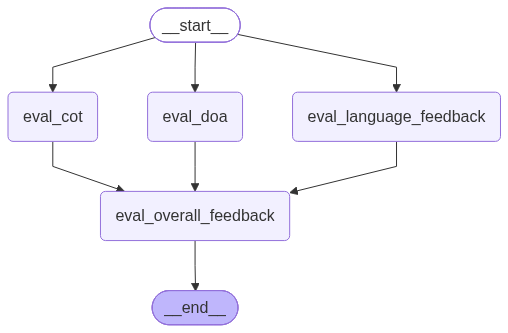

In [57]:
graph = StateGraph(UPSC_essay_eval)

#nodes
graph.add_node('eval_cot', fn_cot)
graph.add_node('eval_doa', fn_doa)
graph.add_node('eval_language_feedback', fn_language_feedback)
graph.add_node('eval_overall_feedback', fn_overall_feedback)
# graph.add_node('cot', fn_cot)

# edges
graph.add_edge(START, 'eval_cot')
graph.add_edge(START, 'eval_doa')
graph.add_edge(START, 'eval_language_feedback')

graph.add_edge('eval_language_feedback', 'eval_overall_feedback')
graph.add_edge('eval_doa', 'eval_overall_feedback')
graph.add_edge('eval_cot', 'eval_overall_feedback')

graph.add_edge('eval_overall_feedback', END)

workflow = graph.compile() 
workflow

In [58]:
initial_state = { "essay" : essay}

workflow.invoke(initial_state)

{'essay': "\nArtificial Intelligence (AI) is playing an increasingly important role in India's growth and development. It is transforming various sectors by improving efficiency, accuracy, and accessibility. In healthcare, AI helps doctors diagnose diseases faster and provide better treatment, while in education, it enables personalized learning and improves access to digital resources. AI also benefits farmers by helping them predict weather conditions, monitor crops, and improve agricultural productivity.\n\nIn the business and financial sectors, AI helps organizations reduce costs, detect fraud, assess financial risks, and enhance customer service. It also contributes to the development of smart cities through improved traffic management and public services. Recognizing its potential, the Indian government is promoting AI research, innovation, and skill development. However, challenges such as job displacement, data privacy, and algorithmic bias must be addressed to ensure its respo